# Leakage-Safe Replication Study: Milk Quality Classification Using Random Forest & Hyperparameter Optimization

**Authors:** Charmele N. Asna, Francis Dave O. Brina, Rolemir Kirk Don D. Zayas  
**Institution:** College of Computing Education, University of Mindanao, Davao City, Philippines  
**Baseline Paper:** Wijaya et al. (2023), *Seafood Quality Detection Using Electronic Nose and Machine Learning Algorithms With Hyperparameter Optimization*  
**Dataset:** Kaggle Milk Quality Dataset (`milknew.csv`)

### Important dataset correction
The original CSV contains 1,059 rows, but 976 rows are exact duplicate records, leaving only **83 unique observations**. To prevent the same observation from appearing in both training and testing data, exact duplicates are removed **before** the train-test split. All final results in this notebook are therefore based on the 83 unique records, not the original 1,059 rows.

### Pipeline
1. Load and inspect the dataset
2. Detect and remove exact duplicate records before splitting
3. Explore class distribution and data quality
4. Perform a stratified 70/30 train-test split
5. Fit StandardScaler on training data only
6. Train the baseline Random Forest
7. Tune Random Forest hyperparameters using 5-fold Stratified GridSearchCV on training data only
8. Evaluate baseline and tuned models on the same untouched test set
9. Compare metrics and confusion matrices
10. Examine feature importance

## Step 1: Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

print("Libraries successfully imported.")

Libraries successfully imported.


## Step 2: Load and Inspect the Dataset
Upload `milknew.csv` to the Colab session if it is not already present.

In [ ]:
import os

CSV_FILENAME = "milknew.csv"

if not os.path.exists(CSV_FILENAME):
    from google.colab import files
    print("Please upload milknew.csv")
    uploaded = files.upload()

df_raw = pd.read_csv(CSV_FILENAME)
df_raw.columns = df_raw.columns.str.strip()

print("Original dataset shape:", df_raw.shape)
display(df_raw.head())
print("\nColumn names:")
print(df_raw.columns.tolist())
print("\nMissing values:")
print(df_raw.isnull().sum())
print("\nDuplicate rows:", df_raw.duplicated().sum())
print("\nOriginal class distribution:")
print(df_raw["Grade"].value_counts())

Original dataset shape: (1059, 8)


,pH,Temprature,Taste,Odor,Fat,Turbidity,Colour,Grade
0,6.6,35,1,0,1,0,254,high
1,6.6,36,0,1,0,1,253,high
2,8.5,70,1,1,1,1,246,low
3,9.5,34,1,1,0,1,255,low
4,6.6,37,0,0,0,0,255,medium



Column names:
['pH', 'Temprature', 'Taste', 'Odor', 'Fat', 'Turbidity', 'Colour', 'Grade']

Missing values:
pH            0
Temprature    0
Taste         0
Odor          0
Fat           0
Turbidity     0
Colour        0
Grade         0
dtype: int64

Duplicate rows: 976

Original class distribution:
Grade
low       429
medium    374
high      256
Name: count, dtype: int64


## Step 3: Remove Exact Duplicates Before Splitting
This step is required to avoid data leakage. If duplicates are left in the dataset, an identical record can be placed in both the training and testing sets.

In [ ]:
duplicate_count = df_raw.duplicated().sum()
df = df_raw.drop_duplicates().reset_index(drop=True)

print(f"Exact duplicate rows removed: {duplicate_count}")
print(f"Rows before deduplication: {len(df_raw)}")
print(f"Rows after deduplication:  {len(df)}")
print(f"Unique-data retention: {len(df)/len(df_raw)*100:.2f}%")

print("\nClass distribution after deduplication:")
print(df["Grade"].value_counts())
print("\nRemaining duplicate rows:", df.duplicated().sum())

Exact duplicate rows removed: 976
Rows before deduplication: 1059
Rows after deduplication:  83
Unique-data retention: 7.84%

Class distribution after deduplication:
Grade
medium    34
low       26
high      23
Name: count, dtype: int64

Remaining duplicate rows: 0


## Step 4: Exploratory Data Analysis

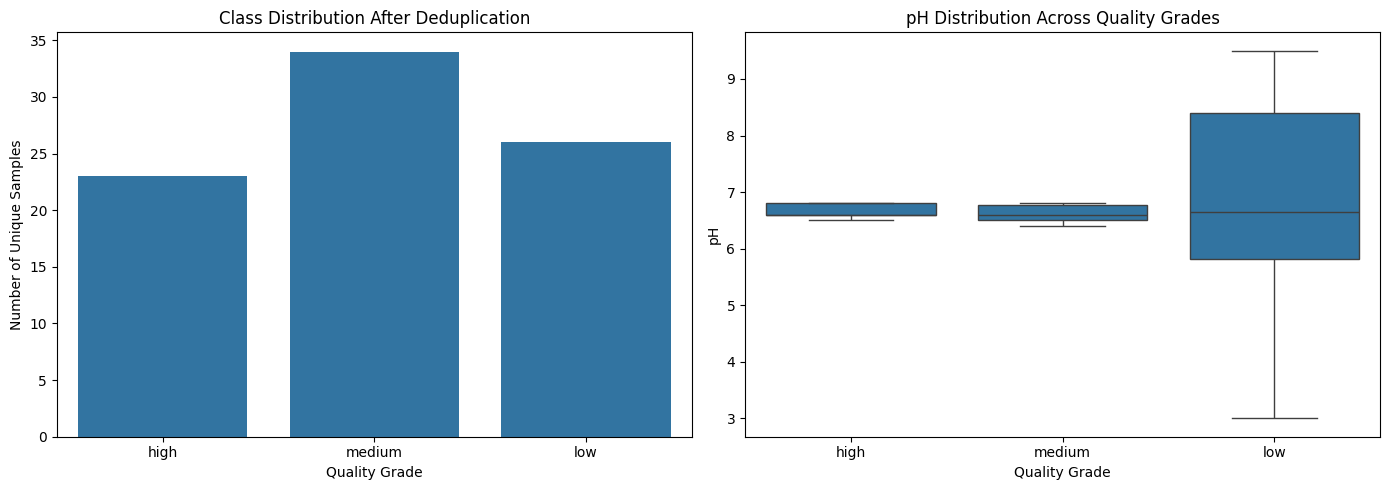

In [ ]:
classes = ["high", "medium", "low"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x="Grade", order=classes, ax=axes[0])
axes[0].set_title("Class Distribution After Deduplication")
axes[0].set_xlabel("Quality Grade")
axes[0].set_ylabel("Number of Unique Samples")

sns.boxplot(data=df, x="Grade", y="pH", order=classes, ax=axes[1])
axes[1].set_title("pH Distribution Across Quality Grades")
axes[1].set_xlabel("Quality Grade")
axes[1].set_ylabel("pH")

plt.tight_layout()
plt.show()

## Step 5: Train-Test Split and Scaling
The cleaned dataset is split using the same 70/30 structure as the baseline methodology. Stratification preserves the class proportions. The scaler is fitted only on the training data.

In [ ]:
X = df.drop(columns=["Grade"])
y = df["Grade"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

print(f"Unique observations: {len(df)}")
print(f"Training samples: {len(X_train)} ({len(X_train)/len(df)*100:.1f}%)")
print(f"Testing samples:  {len(X_test)} ({len(X_test)/len(df)*100:.1f}%)")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
joblib.dump(scaler, "scaler.joblib")

print("\nTraining class distribution:")
print(y_train.value_counts())
print("\nTesting class distribution:")
print(y_test.value_counts())

Unique observations: 83
Training samples: 58 (69.9%)
Testing samples:  25 (30.1%)

Training class distribution:
Grade
medium    24
low       18
high      16
Name: count, dtype: int64

Testing class distribution:
Grade
medium    10
low        8
high       7
Name: count, dtype: int64


## Step 6: Baseline Random Forest

In [ ]:
rf_baseline = RandomForestClassifier(
    criterion="gini",
    n_estimators=100,
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

rf_baseline.fit(X_train_scaled, y_train)
y_pred_base = rf_baseline.predict(X_test_scaled)

def evaluate_model(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, average="weighted", zero_division=0)
    }

base_metrics = evaluate_model(y_test, y_pred_base)
print("=== BASELINE RANDOM FOREST ===")
for metric, value in base_metrics.items():
    print(f"{metric}: {value*100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_base, digits=4, zero_division=0))

=== BASELINE RANDOM FOREST ===
Accuracy: 72.00%
Precision: 76.00%
Recall: 72.00%
F1-Score: 72.28%

Classification Report:
              precision    recall  f1-score   support

        high     0.5000    0.5714    0.5333         7
         low     1.0000    0.6250    0.7692         8
      medium     0.7500    0.9000    0.8182        10

    accuracy                         0.7200        25
   macro avg     0.7500    0.6988    0.7069        25
weighted avg     0.7600    0.7200    0.7228        25



## Step 7: Hyperparameter Tuning with 5-Fold Grid Search
The search is performed only on the training data. The test set is not used during hyperparameter selection. The search space below contains 64 parameter combinations and 320 total fits (64 × 5 folds).

In [ ]:
param_grid_rf = {
    "criterion": ["gini", "entropy"],
    "n_estimators": [20, 100],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 10],
    "min_samples_leaf": [1, 5]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid_rf,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

print("Number of parameter combinations:", len(list(__import__("sklearn").model_selection.ParameterGrid(param_grid_rf))))
print("Total cross-validation fits:", len(list(__import__("sklearn").model_selection.ParameterGrid(param_grid_rf))) * 5)

grid_rf.fit(X_train_scaled, y_train)
best_rf = grid_rf.best_estimator_
joblib.dump(best_rf, "best_random_forest_model.joblib")

print("\n=== GRID SEARCH RESULTS ===")
print("Best hyperparameters:", grid_rf.best_params_)
print(f"Best 5-Fold CV Accuracy: {grid_rf.best_score_ * 100:.2f}%")

Number of parameter combinations: 64
Total cross-validation fits: 320
Fitting 5 folds for each of 64 candidates, totalling 320 fits

=== GRID SEARCH RESULTS ===
Best hyperparameters: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 20}
Best 5-Fold CV Accuracy: 84.70%


In [ ]:
tuning_results = pd.DataFrame(grid_rf.cv_results_)[[
    "param_criterion", "param_n_estimators", "param_max_depth",
    "param_min_samples_split", "param_min_samples_leaf",
    "mean_test_score", "std_test_score", "rank_test_score"
]].copy()

tuning_results["mean_test_score"] *= 100
tuning_results["std_test_score"] *= 100
tuning_results = tuning_results.sort_values("mean_test_score", ascending=False)

print("Top 10 Grid Search Configurations:")
display(tuning_results.head(10))

Top 10 Grid Search Configurations:


,param_criterion,param_n_estimators,param_max_depth,param_min_samples_split,param_min_samples_leaf,mean_test_score,std_test_score,rank_test_score
8,gini,20,10,2,1,84.696970,8.248883,1
16,gini,20,15,2,1,84.696970,8.248883,1
24,gini,20,None,2,1,84.696970,8.248883,1
9,gini,100,10,2,1,82.878788,7.307367,4
17,gini,100,15,2,1,82.878788,7.307367,4
25,gini,100,None,2,1,82.878788,7.307367,4
1,gini,100,5,2,1,82.727273,5.322475,7
0,gini,20,5,2,1,81.212121,5.934290,8
48,entropy,20,15,2,1,81.212121,9.527400,8
49,entropy,100,15,2,1,81.212121,5.934290,8


## Step 8: Evaluate the Tuned Model on the Unseen Test Set

In [ ]:
y_pred_opt = best_rf.predict(X_test_scaled)
opt_metrics = evaluate_model(y_test, y_pred_opt)

print("=== TUNED RANDOM FOREST ===")
for metric, value in opt_metrics.items():
    print(f"{metric}: {value*100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_opt, digits=4, zero_division=0))

comparison = pd.DataFrame({"Baseline RF": base_metrics, "Tuned RF": opt_metrics})
comparison["Improvement (percentage points)"] = (comparison["Tuned RF"] - comparison["Baseline RF"]) * 100
print("\n=== PERFORMANCE COMPARISON ===")
display(comparison.style.format({"Baseline RF":"{:.2%}", "Tuned RF":"{:.2%}", "Improvement (percentage points)":"{:+.2f}"}))

=== TUNED RANDOM FOREST ===
Accuracy: 80.00%
Precision: 84.80%
Recall: 80.00%
F1-Score: 80.38%

Classification Report:
              precision    recall  f1-score   support

        high     0.6000    0.8571    0.7059         7
         low     1.0000    0.6250    0.7692         8
      medium     0.9000    0.9000    0.9000        10

    accuracy                         0.8000        25
   macro avg     0.8333    0.7940    0.7917        25
weighted avg     0.8480    0.8000    0.8038        25


=== PERFORMANCE COMPARISON ===


,Baseline RF,Tuned RF,Improvement (percentage points)
Accuracy,72.00%,80.00%,+8.00
Precision,76.00%,84.80%,+8.80
Recall,72.00%,80.00%,+8.00
F1-Score,72.28%,80.38%,+8.10


## Step 11: Confusion Matrices

## Step 9: Visualize Baseline, Tuned, and Comparative Results

The following visualizations summarize the four evaluation metrics—Accuracy, Precision, Recall, and F1-Score—for the baseline and tuned Random Forest models. The charts use the same held-out test set so that the comparison is fair.


### 9.1 Baseline Random Forest Results


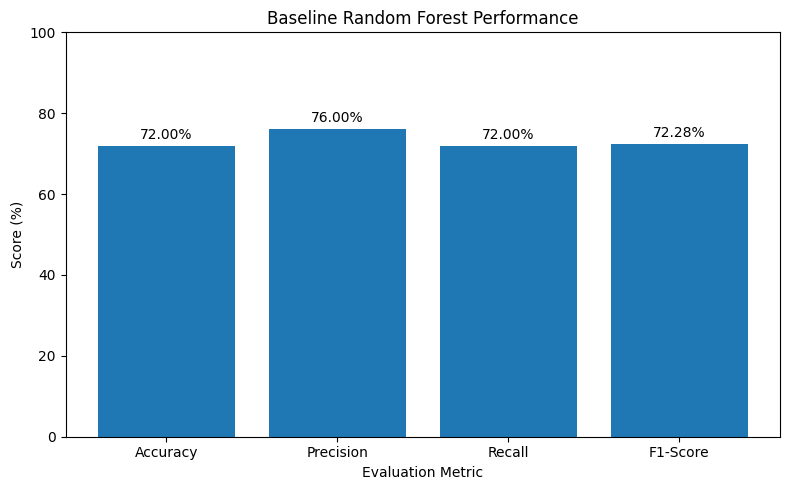

In [ ]:
# Baseline Random Forest performance visualization
baseline_plot = pd.Series(base_metrics) * 100

plt.figure(figsize=(8, 5))
bars = plt.bar(baseline_plot.index, baseline_plot.values)
plt.ylim(0, 100)
plt.ylabel("Score (%)")
plt.xlabel("Evaluation Metric")
plt.title("Baseline Random Forest Performance")

for bar, value in zip(bars, baseline_plot.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("baseline_random_forest_results.png", dpi=300, bbox_inches="tight")
plt.show()


### 9.2 Tuned Random Forest Results


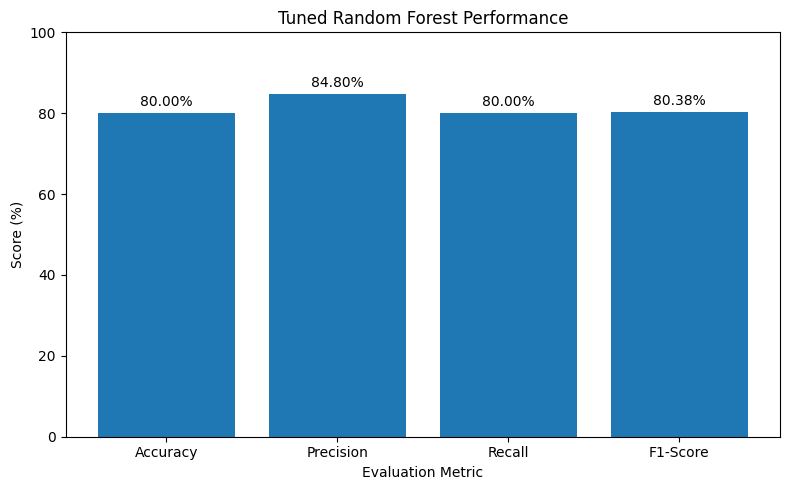

In [ ]:
# Tuned Random Forest performance visualization
tuned_plot = pd.Series(opt_metrics) * 100

plt.figure(figsize=(8, 5))
bars = plt.bar(tuned_plot.index, tuned_plot.values)
plt.ylim(0, 100)
plt.ylabel("Score (%)")
plt.xlabel("Evaluation Metric")
plt.title("Tuned Random Forest Performance")

for bar, value in zip(bars, tuned_plot.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig("tuned_random_forest_results.png", dpi=300, bbox_inches="tight")
plt.show()


### 9.3 Baseline vs. Tuned Random Forest


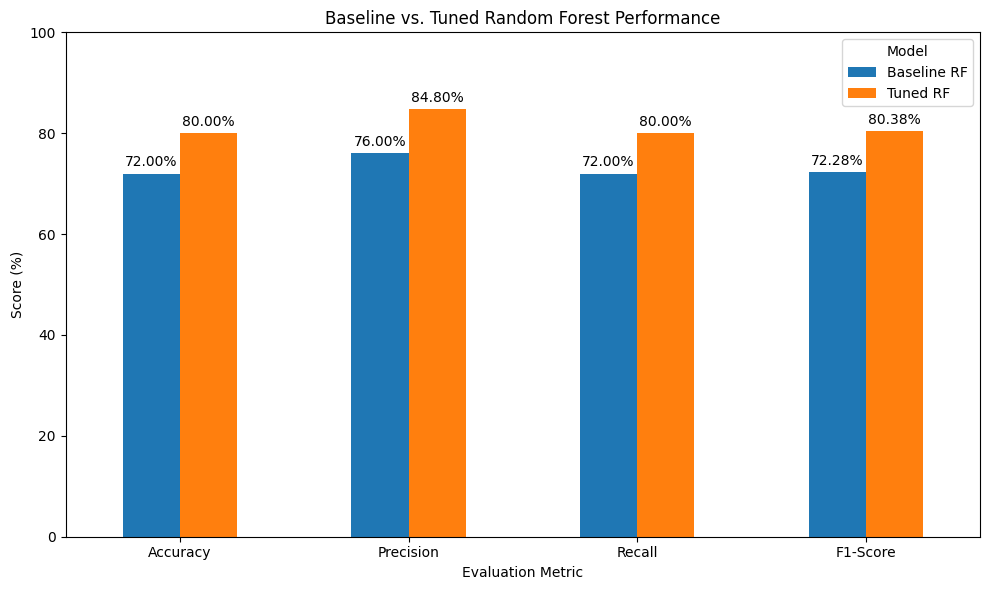

In [ ]:
# Direct comparison of baseline and tuned Random Forest
comparison_plot = comparison[["Baseline RF", "Tuned RF"]] * 100

ax = comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylim(0, 100)
plt.ylabel("Score (%)")
plt.xlabel("Evaluation Metric")
plt.title("Baseline vs. Tuned Random Forest Performance")
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.legend(title="Model")
plt.tight_layout()
plt.savefig("baseline_vs_tuned_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


## Step 10: Parameter Experimentation

Because this study focuses on Random Forest hyperparameter tuning, the following experiment tests individual hyperparameters using five-fold stratified cross-validation on the training data only.

The test set is **not used** during these experiments. This prevents the test data from influencing parameter selection.

The experiments vary:
- `n_estimators` – number of trees
- `max_depth` – maximum depth of each tree
- `min_samples_split` – minimum samples needed to split a node
- `min_samples_leaf` – minimum samples allowed in a leaf
- `criterion` – function used to measure split quality

The remaining parameters are kept at the selected tuned configuration while one parameter is changed at a time. The results are useful for explaining how different parameter values affect cross-validation performance.


In [ ]:
# Parameter experimentation using training data only

best_params = grid_rf.best_params_.copy()

parameter_experiments = {
    "n_estimators": [10, 20, 50, 100, 200],
    "max_depth": [3, 5, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10, 15, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "criterion": ["gini", "entropy"]
}

experiment_results = {}

for parameter, values in parameter_experiments.items():
    rows = []

    for value in values:
        params = best_params.copy()
        params[parameter] = value

        model = RandomForestClassifier(
            **params,
            random_state=42,
            n_jobs=-1
        )

        scores = []
        for train_idx, val_idx in cv.split(X_train_scaled, y_train):
            X_tr = X_train_scaled[train_idx]
            X_val = X_train_scaled[val_idx]
            y_tr = y_train.iloc[train_idx]
            y_val = y_train.iloc[val_idx]

            model.fit(X_tr, y_tr)
            predictions = model.predict(X_val)
            scores.append(accuracy_score(y_val, predictions))

        rows.append({
            "Parameter": parameter,
            "Value": str(value),
            "Mean CV Accuracy": np.mean(scores) * 100,
            "Std CV Accuracy": np.std(scores) * 100
        })

    experiment_results[parameter] = pd.DataFrame(rows)

# Display all parameter experiment results
for parameter, result in experiment_results.items():
    print(f"=== {parameter} experiment ===")
    display(result.sort_values("Mean CV Accuracy", ascending=False))


=== n_estimators experiment ===


,Parameter,Value,Mean CV Accuracy,Std CV Accuracy
1,n_estimators,20,84.696970,8.248883
2,n_estimators,50,84.545455,6.184343
0,n_estimators,10,82.878788,10.932215
3,n_estimators,100,82.878788,7.307367
4,n_estimators,200,79.242424,6.920113


=== max_depth experiment ===


,Parameter,Value,Mean CV Accuracy,Std CV Accuracy
3,max_depth,15,84.696970,8.248883
2,max_depth,10,84.696970,8.248883
4,max_depth,20,84.696970,8.248883
5,max_depth,None,84.696970,8.248883
1,max_depth,5,81.212121,5.934290
0,max_depth,3,79.393939,8.290524


=== min_samples_split experiment ===


,Parameter,Value,Mean CV Accuracy,Std CV Accuracy
1,min_samples_split,5,88.030303,6.523955
0,min_samples_split,2,84.696970,8.248883
3,min_samples_split,15,80.909091,6.697587
4,min_samples_split,20,80.909091,6.697587
2,min_samples_split,10,79.242424,6.920113


=== min_samples_leaf experiment ===


,Parameter,Value,Mean CV Accuracy,Std CV Accuracy
0,min_samples_leaf,1,84.696970,8.248883
1,min_samples_leaf,2,82.727273,5.322475
2,min_samples_leaf,5,75.757576,3.921872
3,min_samples_leaf,10,58.484848,6.883525


=== criterion experiment ===


,Parameter,Value,Mean CV Accuracy,Std CV Accuracy
0,criterion,gini,84.696970,8.248883
1,criterion,entropy,81.212121,9.527400


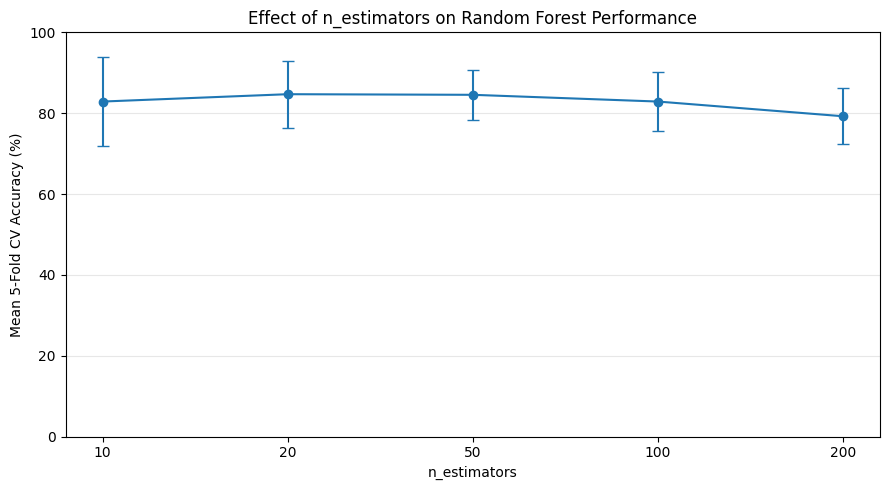

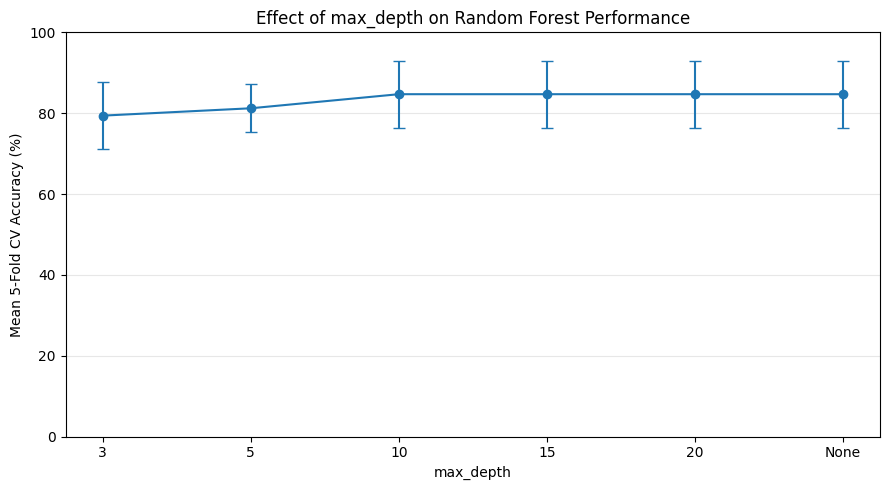

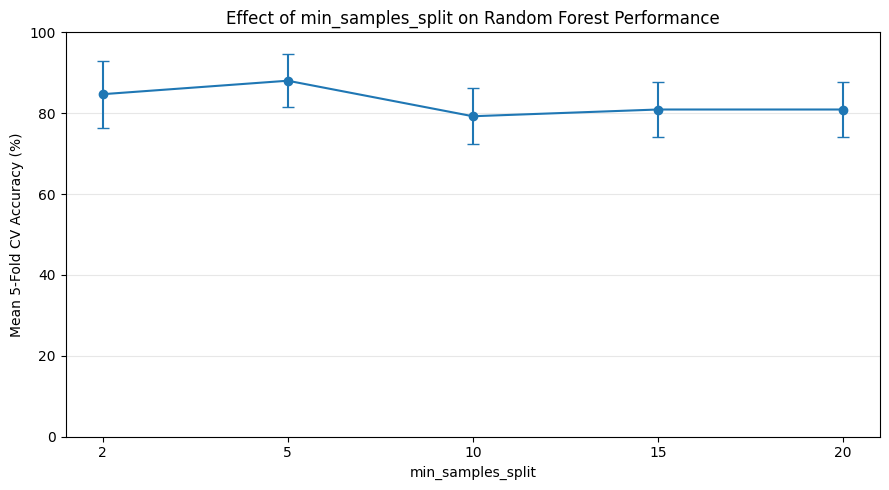

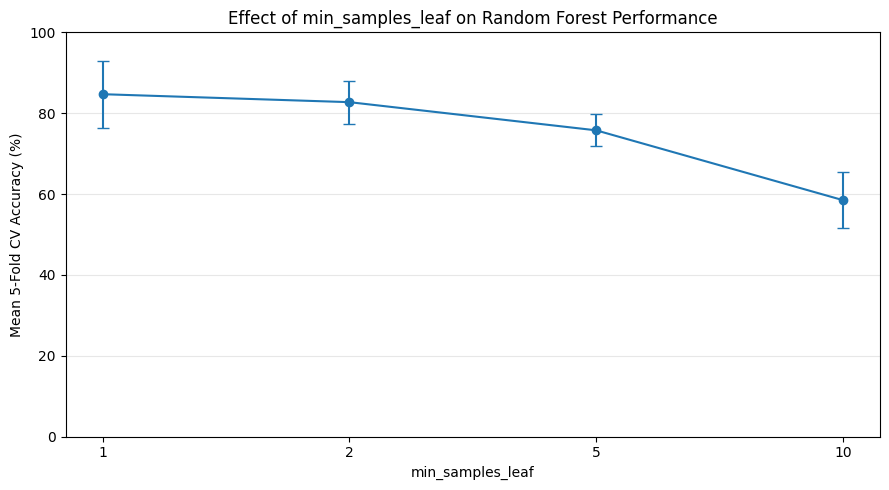

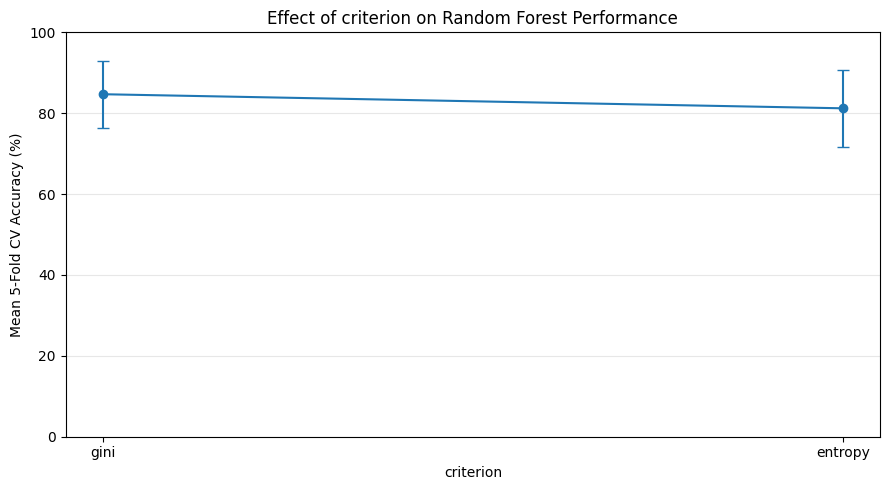

In [ ]:
# Visualize the effect of each hyperparameter on cross-validation accuracy

for parameter, result in experiment_results.items():
    plt.figure(figsize=(9, 5))

    x_labels = result["Value"].tolist()
    x_positions = np.arange(len(x_labels))

    plt.errorbar(
        x_positions,
        result["Mean CV Accuracy"],
        yerr=result["Std CV Accuracy"],
        marker="o",
        capsize=4
    )

    plt.xticks(x_positions, x_labels)
    plt.ylabel("Mean 5-Fold CV Accuracy (%)")
    plt.xlabel(parameter)
    plt.title(f"Effect of {parameter} on Random Forest Performance")
    plt.ylim(0, 100)
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.savefig(f"parameter_experiment_{parameter}.png", dpi=300, bbox_inches="tight")
    plt.show()


### How to interpret the parameter experiments

These experiments do not replace Grid Search. They provide additional evidence showing how changing individual Random Forest parameters affects cross-validation accuracy.

For the final model, the **Grid Search result remains the main basis for selecting the tuned hyperparameters**, while the parameter experiments are used to discuss why different parameter settings can produce different results.


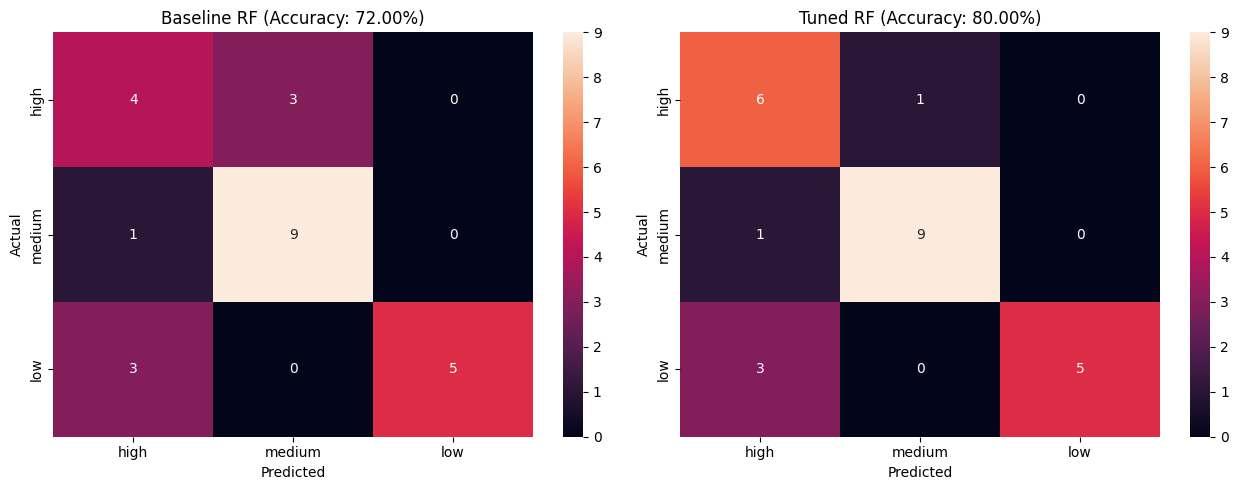

Baseline confusion matrix:
[[4 3 0]
 [1 9 0]
 [3 0 5]]

Tuned confusion matrix:
[[6 1 0]
 [1 9 0]
 [3 0 5]]


In [ ]:
cm_base = confusion_matrix(y_test, y_pred_base, labels=classes)
cm_opt = confusion_matrix(y_test, y_pred_opt, labels=classes)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm_base, annot=True, fmt="d", xticklabels=classes, yticklabels=classes, ax=axes[0])
axes[0].set_title(f"Baseline RF (Accuracy: {base_metrics['Accuracy']*100:.2f}%)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(cm_opt, annot=True, fmt="d", xticklabels=classes, yticklabels=classes, ax=axes[1])
axes[1].set_title(f"Tuned RF (Accuracy: {opt_metrics['Accuracy']*100:.2f}%)")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.savefig("confusion_matrices_comparison.png", dpi=300)
plt.show()

print("Baseline confusion matrix:")
print(cm_base)
print("\nTuned confusion matrix:")
print(cm_opt)

## Step 12: Feature Importance

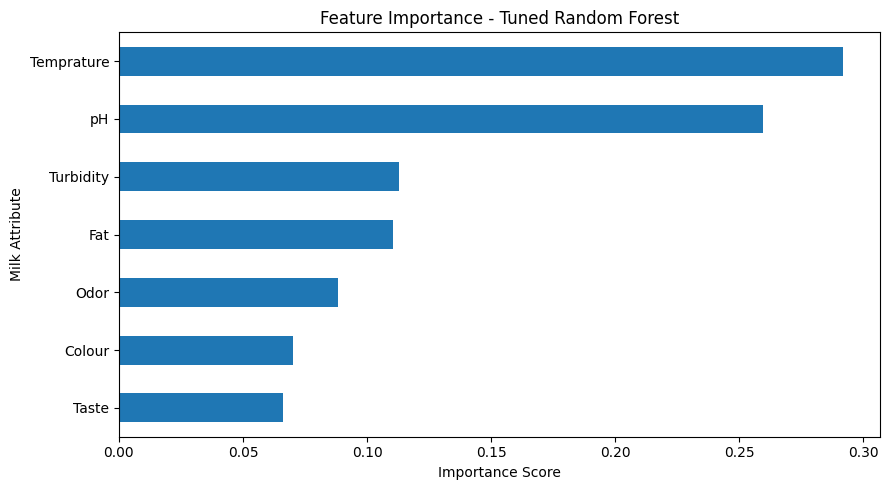

Feature Ranking:
1. Temprature: 29.19%
2. pH: 25.97%
3. Turbidity: 11.31%
4. Fat: 11.06%
5. Odor: 8.81%
6. Colour: 7.03%
7. Taste: 6.63%


In [ ]:
feat_importances = pd.Series(
    best_rf.feature_importances_, index=X.columns
).sort_values(ascending=True)

plt.figure(figsize=(9, 5))
feat_importances.plot(kind="barh")
plt.title("Feature Importance - Tuned Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Milk Attribute")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=300)
plt.show()

print("Feature Ranking:")
for rank, (feature, value) in enumerate(feat_importances.sort_values(ascending=False).items(), 1):
    print(f"{rank}. {feature}: {value*100:.2f}%")

## Step 11: Leakage Check Summary

The final experiment uses the following safeguards:
- Exact duplicate records are removed before the train-test split.
- The test set is kept untouched during Grid Search.
- Stratified splitting is used because the target has three classes.
- StandardScaler is fitted only on the training data and then applied to the test data.

**Important:** Because only 83 unique observations remain, the final test set contains only 25 observations. The resulting metrics should therefore be interpreted cautiously and should not be presented as evidence of 99%+ generalization performance.